# **Infer `Cellmask` and `Nucleus`**

***Prior to this notebook, you should have already run through [1.0_image_setup](1.0_image_setup.ipynb).***

In notebooks 1.1 through 1.8, we will go over the implementation of `infer-subc` in the Napari plugin called  `organelle-segmenter-plugin`. The steps outlined in each notebook correlate to the workflow steps from the plugin. Here, you will gain knowledge of what `infer-subc` functions are involved in each of those steps.

The segmentation workflows are completely independent of each other and can be run in any order. The current notebook segments the `cell mask` and `nucleus` based on a multichannel input image. See below for more details on the input image type required. Consider the other versions of notebooks 1.1 outlined below as well.

## **SANDBOX FOR: Improved cell/nuclei segmentation**
<ins>Goals:</ins> Improve cell mask segmentation by implementing a machine learning approach.

includes stardist segmentation from copilot

--------------


---------------------
----------
# **IMPORTS AND LOAD IMAGE**
Details about the functions included in this subsection are outlined in the [`1.0_image_setup`](1.0_image_setup.ipynb) notebook. Please visit that notebook first if you are confused about any of the code included here.

#### &#x1F3C3; **Run code; no user input required**

In [5]:
from pathlib import Path
import os
import seaborn as sns

import numpy as np
import pandas as pd
import napari
from napari.utils.notebook_display import nbscreenshot

from skimage.morphology import binary_dilation, binary_erosion

from infer_subc.core.file_io import (read_czi_image, 
                                     export_inferred_organelle,
                                     list_image_files,
                                     sample_input)
from infer_subc.core.img import *
from infer_subc.organelles.membrane import *
from infer_subc.organelles.nuclei import infer_nuclei_fromcytoplasm

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information about your data: `sample_data_type`, `data_root_path`, `in_data_path`, `im_type`, and `out_data_path`.

In [6]:
### USER INPUT REQUIRED ###
sample_data_type = None


# Edit locations indicated by "USER SPECIFIED".
data_root_path = Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data")

in_data_path = data_root_path / "example-images"

im_type = ".tiff"

out_data_path = data_root_path / "202610012_testing-outputs/images_for_figures"

vis_path = data_root_path / "20261029_SR_test-sd"

#### &#x1F3C3; **Run code; no user input required**

In [7]:
# If sample_data_type is set to "neuron_1", "astrocyte", "neuron_2" or "iPSC" then the sample data is used and the directories are set
if sample_data_type != None:
    data_root_path, im_type, in_data_path, out_data_path = sample_input(sample_data_type)

# Create the output directory to save the segmentation outputs in.
if not Path.exists(out_data_path):
    Path.mkdir(out_data_path)
    print(f"making {out_data_path}")

if not Path.exists(vis_path):
    Path.mkdir(vis_path)
    print(f"making {vis_path}")

# Create a list of the file paths for each image in the input folder. Select test image path.
img_file_list = list_image_files(in_data_path,im_type)
pd.set_option('display.max_colwidth', None)
pd.DataFrame({"Image Name":img_file_list})

,Image Name
0,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\02242026_ZS_iPSCs_SOX9NFIA1_BR02_N07_Unmixing_cmle.ome.tiff
1,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\03172026_ZS_iPSCs_SOX9NFIA1_BR03_N03_Unmixing_cmle.ome.tiff
2,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N07_Unmixing_cmle.ome.tiff
3,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N11_Unmixing_cmle.ome.tiff
4,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img11_zstack_Unmixing_decon.ome.tiff
5,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\11192025_iNeurons_day_14_BFP2EEA1_mTurLAMP1_OxVenSiT_mAppRab11_PM_img18_zstack_Unmixing_decon.ome.tiff
6,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
7,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff


#### &#x1F6D1; &#x270D; **User Input Required:**

Use the list above to specify which image you wish to analyze based on its index: `test_img_n`

In [8]:
#### USER INPUT REQUIRED ###
test_img_n = 7

#### &#x1F3C3; **Run code; no user input required**

Attempted file (C:/Users/Shannon/Desktop/Cell-nuc-mask_test-data/example-images/20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff) load with reader: aicsimageio.readers.bfio_reader.OmeTiledTiffReader failed with error: No module named 'bfio'


Metadata information
File path: C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff
File name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff
Channel 0 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 0
Channel 1 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 1
Channel 2 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 2
Channel 3 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 3
Channel 4 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 4
Channel 5 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 5
Channel 6 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 6
Channel 7 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 7
Channel 8 name: 20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome :: Channel 8
Channel 9 name: 20260813_wtc


Proceed to Napari window to view your selected image.


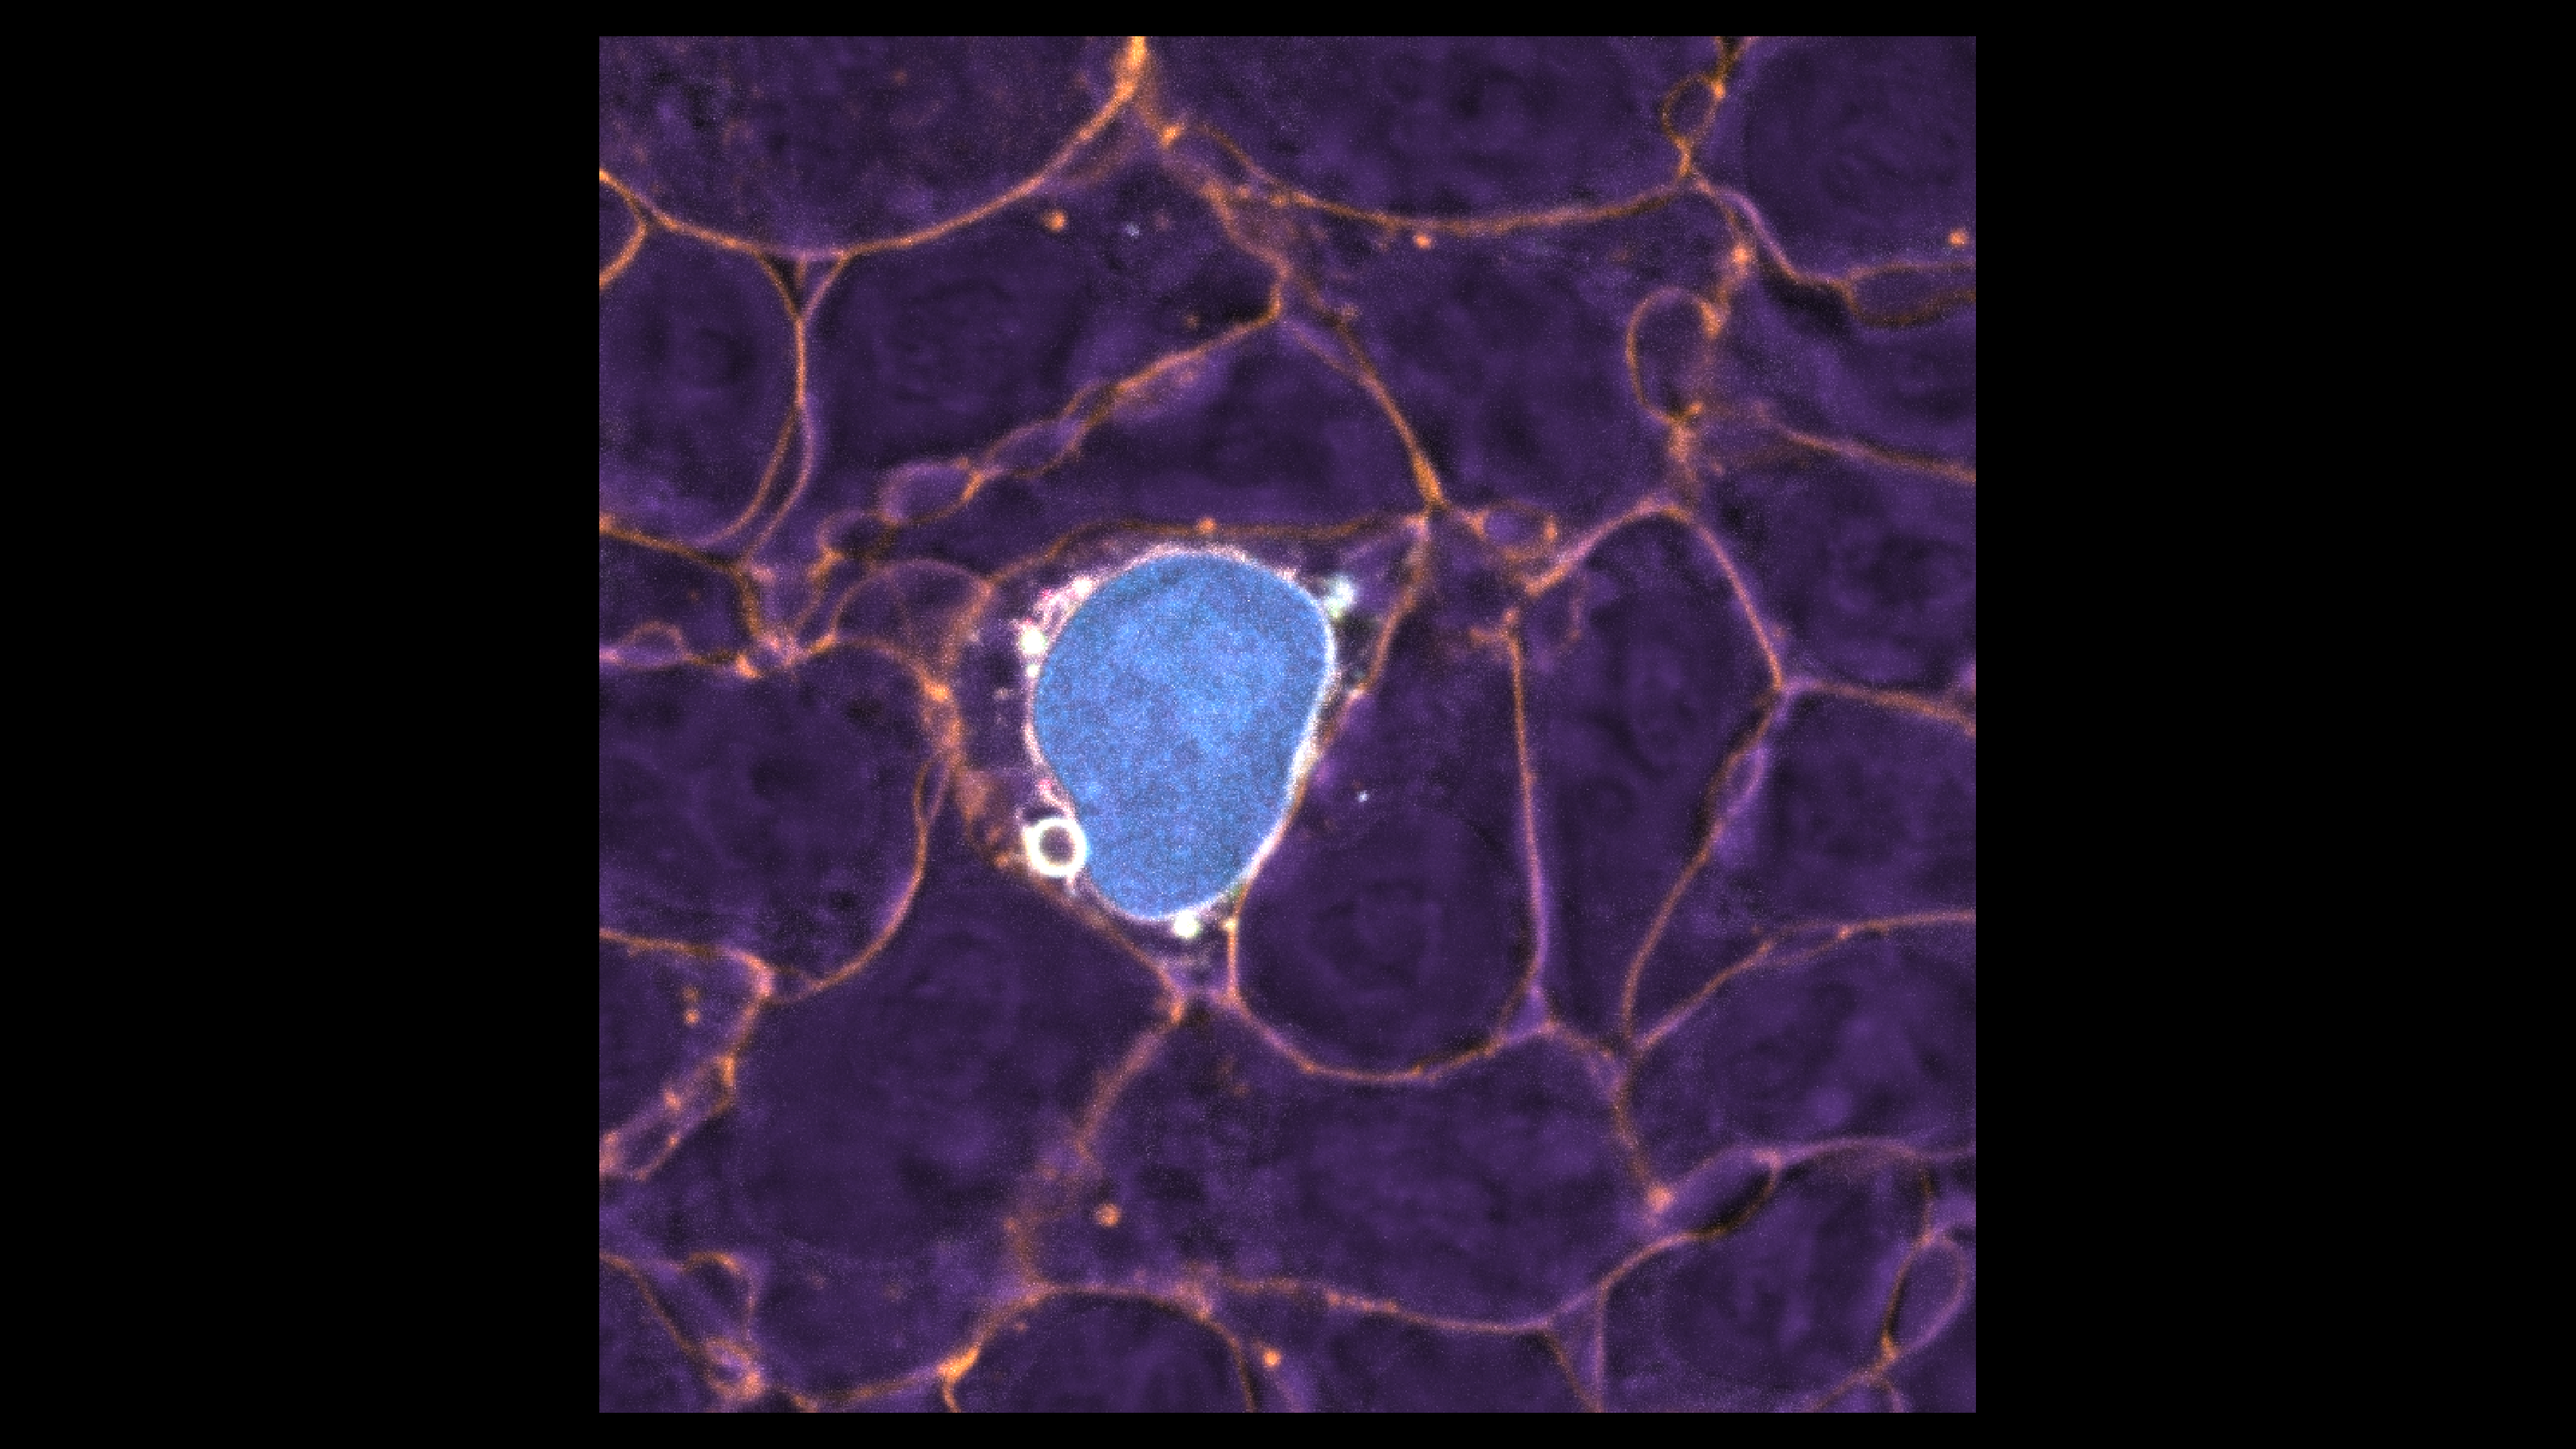

In [12]:
# Read in the image and metadata as an ndarray and dictionary from the test image selected above. 
test_img_name = img_file_list[test_img_n]
img_data,meta_dict = read_czi_image(test_img_name)

# Define some of the metadata features and print them.
channel_names = meta_dict['name']
meta = meta_dict['metadata']['aicsimage']
scale = meta_dict['scale']
channel_axis = meta_dict['channel_axis']
file_path = meta_dict['file_name']
file_name = str(meta_dict['file_name']).split("\\")[-1]

print("Metadata information")
print(f"File path: {file_path}")
print(f"File name: {file_name}")
for i in list(range(len(channel_names))):
    print(f"Channel {i} name: {channel_names[i]}")
print(f"Scale (ZYX): {scale}")
print(f"Channel axis: {channel_axis}")

# open viewer and add images
viewer = napari.Viewer()
color_map = sns.color_palette("Paired").as_hex()
for i in list(range(len(channel_names))):
    # add image to viewer
    viewer.add_image(img_data[i],
                     scale=scale,
                     name=f"Channel {i}",
                     blending='additive',
                     colormap=color_map[i])
viewer.grid.enabled = False
viewer.reset_view()
print("\nProceed to Napari window to view your selected image.")

# screenshot viewer
nbscreenshot(viewer, canvas_only = True)

In [ ]:
# if using a composite of organelles, specify the weights here, else leave them as 0/None
use_composite = True
invert_pm = False
PM_CH = 7
w0 = 0
w1 = 2
w2 = 2
w3 = 2
w4 = 2
w5 = 2
w6 = 2
w7 = 0
w8 = 0
w9 = 0

if use_composite:
    composite = struct_img_raw_I = membrane_composite(img_data,
                                                        weight_ch0= w0,
                                                        weight_ch1= w1,
                                                        weight_ch2= w2,
                                                        weight_ch3= w3,
                                                        weight_ch4= w4,
                                                        weight_ch5= w5,
                                                        weight_ch6= w6,
                                                        weight_ch7= w7,
                                                        weight_ch8= w8,
                                                        weight_ch9= w9,
                                                        Invert_PM = invert_pm,
                                                        PM_Channel = PM_CH)

    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')

5294730/5294730 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5231396/5231396 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5298331/5298331 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


-----
-----
# **ALTERNATIVE: Stardist 3D segmentation of `Cellmask` and `Nucleus`**

This section uses StarDist to predict nuclei from the nuclear stain and cell instances from a composite of cytoplasmic organelle channels. Both 3D and slice-by-slice 2D routes are available for comparison.

- **Composite:** channels 0–6 are independently intensity-normalized and averaged so organelles and nuclei contribute to a single cytoplasm-filled image. The channel 7 plasma-membrane marker is excluded by default; optionally add its inverted normalized signal to the composite.
- **3D route:** the same StarDist3D model predicts nuclei from the nuclear stain and cell instances from the composite.
- **2D route:** the same StarDist2D model predicts each Z slice of both inputs, then links adjacent-slice instances by overlap. This is slice-to-slice tracking, not 3D shape prediction.
- **Comparison:** in `both` mode the notebook creates separate nucleus and cell predictions for each model route. The selected primary route determines which cell/nucleus pair is saved. The pretrained models are nucleus models, not cell-trained models; using them on the cytoplasmic composite is experimental, so inspect the label layers carefully.

**Requirements:** `pip install stardist tensorflow` (then restart the kernel). By default both routes run for comparison; choose which route drives the saved stack with `SD_PRIMARY_METHOD`. This section is separate from other segmentation workflows and saves its own output.

#### &#x1F6D1; &#x270D; **User Input Required:**

- `SD_NUC_CH` (default `1`): zero-based index of the nuclear-stain channel in `img_data`. This channel is the StarDist nucleus input.
- `SD_CELL_CHANNELS` (default `(0, 1, 2, 3, 4, 5, 6)`): zero-based intensity channels averaged to form the cell composite. These should be the cytoplasmic organelle/nucleus signals.
- `SD_PM_CH` (default `7`): zero-based index of the plasma-membrane marker. It is excluded from the composite unless `SD_CELL_USE_INVERTED_PM=True`.
- `SD_CELL_USE_INVERTED_PM` (default `False`): whether to include the inverted, normalized membrane signal as an optional extra composite component.
- `SD_CELL_PM_WEIGHT` (default `1.0`): relative contribution of the inverted membrane image when enabled; larger values increase its influence.
- `SD_NUCLEI_MODE` (`"3d"`, `"2d"`, or `"both"`; default `"both"`): selects which model route(s) predict both nuclei and cell instances.
- `SD_PRIMARY_METHOD` (`"3d"` or `"2d"`; default `"3d"`): selects which route's cell/nucleus results are saved. If only one route runs, this must match `SD_NUCLEI_MODE`.
- `SD_MODEL` (default `"3D_demo"`): StarDist3D pretrained model alias or path to a folder containing a trained StarDist3D model (`config.json` and weights). The demo model is a baseline, not a model trained specifically for these images.
- `SD_2D_MODEL` (default `"2D_versatile_fluo"`): StarDist2D pretrained model alias or path to a folder containing a trained StarDist2D model. `2D_versatile_fluo` is intended for fluorescent nuclei.
- `SD_3D_PROB_THRESH` / `SD_2D_PROB_THRESH` (default `None`): object probability cutoff for each model, applied to both its nucleus and composite predictions. `None` uses the model's stored threshold. Lower values generally accept more candidate objects; higher values are stricter.
- `SD_3D_NMS_THRESH` / `SD_2D_NMS_THRESH` (default `None`): non-maximum-suppression overlap threshold, applied to both inputs for a model route. `None` uses the model's stored value.
- `SD_XY_SCALE` (default `1.0`): positive resize multiplier applied to image Y and X before prediction; e.g. `0.5` halves each dimension. StarDist2D predictions are resized back to the original YX grid. StarDist3D additionally resizes Z to match the model's configured anisotropy and the image voxel scale, then maps labels back to original ZYX.
- `SD_N_TILES` (default `None`): optional StarDist3D prediction tile counts in `(z, y, x)` order, e.g. `(1, 4, 4)`. `None` predicts the full volume at once. Tiling can reduce memory use; tile sizes must satisfy the model's grid requirements.
- `SD_2D_N_TILES` (default `None`): optional StarDist2D prediction tile counts in `(y, x)` order, e.g. `(2, 2)`. `None` predicts each full slice at once. Tiling can reduce memory use; tile sizes must satisfy the model's grid requirements.
- `SD_LINK_IOU` (default `0.1`, range `0` to `1`): minimum intersection-over-union between labels on consecutive Z slices for linking them as the same object. Applied independently to 2D nucleus and composite-cell predictions.
- `CELL_MIN_SIZE` (default `5000`): minimum number of voxels for a composite-based StarDist cell instance to keep. Smaller cell candidates and their matched nuclei are removed.

In [ ]:
#### USER INPUT REQUIRED ####
SD_NUC_CH = 1              # zero-based channel index for nuclear fluorescence
SD_CELL_CHANNELS = tuple(range(7))  # channels averaged for the cytoplasmic composite
SD_PM_CH = 7               # zero-based channel index for plasma membrane fluorescence
SD_CELL_USE_INVERTED_PM = False     # optionally add inverted membrane signal to composite
SD_CELL_PM_WEIGHT = 1.0             # contribution of inverse membrane when enabled

SD_NUCLEI_MODE = 'both'     # routes to run: '3d', '2d', or 'both'
SD_PRIMARY_METHOD = '3d'    # route used for saved cell/nucleus masks: '3d' or '2d'
SD_MODEL = '3D_demo'        # 3D model alias or local StarDist3D model folder
SD_2D_MODEL = '2D_versatile_fluo'  # 2D model alias or local StarDist2D model folder
SD_3D_PROB_THRESH = None    # 3D object probability cutoff; None uses saved model value
SD_3D_NMS_THRESH = None     # 3D overlap suppression cutoff; None uses saved model value
SD_2D_PROB_THRESH = None    # 2D object probability cutoff; None uses saved model value
SD_2D_NMS_THRESH = None     # 2D overlap suppression cutoff; None uses saved model value
SD_XY_SCALE = 1.0           # positive YX resize multiplier before prediction
SD_N_TILES = None           # optional 3D tile counts in (z, y, x) order
SD_2D_N_TILES = None        # optional 2D tile counts in (y, x) order
SD_LINK_IOU = 0.1           # 2D route: min IoU for matching labels across adjacent Z slices (0-1)

CELL_MIN_SIZE = 5000       # minimum retained composite cell volume, in voxels

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** Depending on `SD_NUCLEI_MODE`, this block predicts nuclei with StarDist3D, StarDist2D on each Z slice followed by overlap-based linking, or both. The labels are mapped back to the original image grid.

In [ ]:
from importlib.metadata import version
from csbdeep.utils import normalize
from scipy.optimize import linear_sum_assignment
from stardist.models import StarDist2D, StarDist3D
from skimage.transform import resize

print(f'StarDist {version("stardist")}')
if SD_NUCLEI_MODE not in {'3d', '2d', 'both'}:
    raise ValueError("SD_NUCLEI_MODE must be '3d', '2d', or 'both'")
if SD_PRIMARY_METHOD not in {'3d', '2d'}:
    raise ValueError("SD_PRIMARY_METHOD must be '3d' or '2d'")
if SD_NUCLEI_MODE != 'both' and SD_PRIMARY_METHOD != SD_NUCLEI_MODE:
    raise ValueError('SD_PRIMARY_METHOD must match SD_NUCLEI_MODE unless both methods are run')
if SD_XY_SCALE <= 0:
    raise ValueError('SD_XY_SCALE must be greater than zero')
if not 0 <= SD_LINK_IOU <= 1:
    raise ValueError('SD_LINK_IOU must be between 0 and 1')

def _load_stardist_model(model_class, model_name):
    model_path = Path(model_name)
    if model_path.is_dir():
        return model_class(None, name=model_path.name, basedir=str(model_path.parent))
    try:
        return model_class.from_pretrained(model_name)
    except OSError as exc:
        # StarDist's Windows pretrained-model loader may require symlink privileges.
        if getattr(exc, 'winerror', None) != 1314:
            raise
        extracted = Path.home() / '.keras' / 'models' / model_class.__name__ / model_name / f'{model_name}_extracted'
        if not (extracted / 'config.json').is_file():
            raise
        return model_class(None, name=extracted.name, basedir=str(extracted.parent))

if img_data.ndim != 4:
    raise ValueError(f'Expected channel-first CZYX image data; got shape {img_data.shape}')
if not SD_CELL_CHANNELS or any(c < 0 or c >= img_data.shape[0] for c in SD_CELL_CHANNELS):
    raise ValueError(f'SD_CELL_CHANNELS must select existing image channels; got {SD_CELL_CHANNELS}')
if not 0 <= SD_NUC_CH < img_data.shape[0] or not 0 <= SD_PM_CH < img_data.shape[0]:
    raise ValueError('SD_NUC_CH and SD_PM_CH must select existing image channels')
if SD_NUC_CH not in SD_CELL_CHANNELS:
    raise ValueError('Include the nuclear channel in SD_CELL_CHANNELS so it contributes to the cell composite')
if SD_CELL_PM_WEIGHT < 0:
    raise ValueError('SD_CELL_PM_WEIGHT must be non-negative')
if CELL_MIN_SIZE < 0:
    raise ValueError('CELL_MIN_SIZE must be non-negative')

def _scale_channel(channel):
    channel = np.asarray(channel, dtype=np.float32)
    low, high = np.percentile(channel, (1, 99.8))
    if high <= low:
        return np.zeros_like(channel)
    return np.clip((channel - low) / (high - low), 0, 1)

cell_composite = np.zeros_like(img_data[SD_NUC_CH], dtype=np.float32)
for channel_index in SD_CELL_CHANNELS:
    cell_composite += _scale_channel(img_data[channel_index])
cell_composite /= len(SD_CELL_CHANNELS)
if SD_CELL_USE_INVERTED_PM:
    inverted_pm = 1 - _scale_channel(img_data[SD_PM_CH])
    cell_composite = (cell_composite + SD_CELL_PM_WEIGHT * inverted_pm) / (1 + SD_CELL_PM_WEIGHT)
viewer.add_image(cell_composite, scale=scale, name='StarDist cell composite', blending='additive')

orig_shape = img_data[SD_NUC_CH].shape
nuclei_by_method = {}
cells_by_method = {}

if SD_NUCLEI_MODE in {'3d', 'both'}:
    model_3d = _load_stardist_model(StarDist3D, SD_MODEL)
    model_aniso = model_3d.config.anisotropy or (1, 1, 1)
    z_zoom = (scale[0] / scale[1]) / (model_aniso[0] / model_aniso[1])
    work_shape = (max(1, round(orig_shape[0] * z_zoom)),
                  max(1, round(orig_shape[1] * SD_XY_SCALE)),
                  max(1, round(orig_shape[2] * SD_XY_SCALE)))
    def _predict_3d(volume):
        volume = np.asarray(volume, dtype=np.float32)
        if work_shape != orig_shape:
            volume = resize(volume, work_shape, order=1, anti_aliasing=True, preserve_range=True).astype(np.float32)
        volume = normalize(volume, 1, 99.8, axis=(0, 1, 2))
        labels, _ = model_3d.predict_instances(volume, prob_thresh=SD_3D_PROB_THRESH,
                                                nms_thresh=SD_3D_NMS_THRESH, n_tiles=SD_N_TILES)
        if labels.shape != orig_shape:
            labels = resize(labels, orig_shape, order=0, anti_aliasing=False, preserve_range=True)
        return labels.astype(np.uint32)

    nuclei_by_method['3d'] = _predict_3d(img_data[SD_NUC_CH])
    cells_by_method['3d'] = _predict_3d(cell_composite)
    print(f'3D nuclei found: {len(np.unique(nuclei_by_method["3d"])) - 1}; '
          f'cell candidates from composite: {len(np.unique(cells_by_method["3d"])) - 1}')

def _predict_stardist2d_slices(model_2d, volume):
    """Predict each Z plane and link labels in neighboring planes by one-to-one IoU matching."""
    z_count, height, width = volume.shape
    target_shape = (max(1, round(height * SD_XY_SCALE)), max(1, round(width * SD_XY_SCALE)))
    linked = np.zeros((z_count, height, width), dtype=np.uint32)
    next_label = 1
    previous = None
    for z in range(z_count):
        plane = np.asarray(volume[z], dtype=np.float32)
        if plane.shape != target_shape:
            plane = resize(plane, target_shape, order=1, anti_aliasing=True, preserve_range=True).astype(np.float32)
        plane = normalize(plane, 1, 99.8, axis=(0, 1))
        local, _ = model_2d.predict_instances(plane, prob_thresh=SD_2D_PROB_THRESH,
                                              nms_thresh=SD_2D_NMS_THRESH, n_tiles=SD_2D_N_TILES)
        if local.shape != (height, width):
            local = resize(local, (height, width), order=0, anti_aliasing=False, preserve_range=True)
        local = local.astype(np.uint32)
        local_ids = np.unique(local)
        local_ids = local_ids[local_ids > 0]
        mapping = np.zeros(int(local.max()) + 1, dtype=np.uint32)
        if previous is not None and local_ids.size:
            previous_ids = np.unique(previous)
            previous_ids = previous_ids[previous_ids > 0]
            overlap = (previous > 0) & (local > 0)
            if overlap.any() and previous_ids.size:
                pairs, intersections = np.unique(
                    np.stack((previous[overlap], local[overlap]), axis=1), axis=0, return_counts=True
                )
                prev_area = np.bincount(previous.ravel(), minlength=int(previous_ids.max()) + 1)
                local_area = np.bincount(local.ravel(), minlength=int(local_ids.max()) + 1)
                iou = np.zeros((len(previous_ids), len(local_ids)), dtype=np.float32)
                rows = np.searchsorted(previous_ids, pairs[:, 0])
                cols = np.searchsorted(local_ids, pairs[:, 1])
                denom = prev_area[pairs[:, 0]] + local_area[pairs[:, 1]] - intersections
                iou[rows, cols] = intersections / np.maximum(denom, 1)
                rows, cols = linear_sum_assignment(-iou)
                for row, col in zip(rows, cols):
                    if iou[row, col] > 0 and iou[row, col] >= SD_LINK_IOU:
                        mapping[local_ids[col]] = previous_ids[row]
        for label in local_ids:
            if mapping[label] == 0:
                mapping[label] = next_label
                next_label += 1
        linked[z] = mapping[local]
        previous = linked[z]
    return linked

if SD_NUCLEI_MODE in {'2d', 'both'}:
    model_2d = _load_stardist_model(StarDist2D, SD_2D_MODEL)
    nuclei_by_method['2d'] = _predict_stardist2d_slices(model_2d, img_data[SD_NUC_CH])
    cells_by_method['2d'] = _predict_stardist2d_slices(model_2d, cell_composite)
    print(f'2D-by-slice nuclei found after linking: {len(np.unique(nuclei_by_method["2d"])) - 1}; '
          f'cell candidates from composite: {len(np.unique(cells_by_method["2d"])) - 1}')

for method in nuclei_by_method:
    for kind, labels in [('nuclei', nuclei_by_method[method]), ('cell candidates', cells_by_method[method])]:
        if labels.max() > np.iinfo(np.uint16).max:
            raise OverflowError(f'{method} {kind} produced more than 65535 labels; uint16 output cannot represent them')
        viewer.add_labels(labels.astype(np.uint16), scale=scale, name=f'StarDist {kind} ({method})')

nuc_seg = nuclei_by_method[SD_PRIMARY_METHOD].astype(np.uint32)
cell_seg = cells_by_method[SD_PRIMARY_METHOD].astype(np.uint32)
viewer.grid.enabled = False

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block pairs each StarDist cell candidate from the composite with its best-overlapping StarDist nucleus. Nuclei are clipped to their matched cell, unmatched nuclei are discarded, and cell objects smaller than `CELL_MIN_SIZE` are removed.

In [ ]:
def _pair_nuclei_to_cells(nuclei, cells):
    """Assign at most one nucleus to each cell by maximum overlap and clip it to that cell."""
    nucleus_ids = np.unique(nuclei)
    nucleus_ids = nucleus_ids[nucleus_ids > 0]
    cell_ids = np.unique(cells)
    cell_ids = cell_ids[cell_ids > 0]
    matched_nuclei = np.zeros_like(cells, dtype=np.uint32)
    if not nucleus_ids.size or not cell_ids.size:
        return matched_nuclei

    overlap = (nuclei > 0) & (cells > 0)
    if not overlap.any():
        return matched_nuclei
    pairs, intersections = np.unique(
        np.stack((nuclei[overlap], cells[overlap]), axis=1), axis=0, return_counts=True
    )
    nucleus_size = np.bincount(nuclei.ravel(), minlength=int(nucleus_ids.max()) + 1)
    cell_size = np.bincount(cells.ravel(), minlength=int(cell_ids.max()) + 1)
    iou = np.zeros((len(nucleus_ids), len(cell_ids)), dtype=np.float32)
    rows = np.searchsorted(nucleus_ids, pairs[:, 0])
    cols = np.searchsorted(cell_ids, pairs[:, 1])
    union = nucleus_size[pairs[:, 0]] + cell_size[pairs[:, 1]] - intersections
    iou[rows, cols] = intersections / np.maximum(union, 1)
    rows, cols = linear_sum_assignment(-iou)
    for row, col in zip(rows, cols):
        if iou[row, col] > 0:
            nucleus_id, cell_id = nucleus_ids[row], cell_ids[col]
            matched_nuclei[(nuclei == nucleus_id) & (cells == cell_id)] = cell_id
    return matched_nuclei

cell_results = {}
for method, raw_cells in cells_by_method.items():
    cell_labels = raw_cells.copy()
    sizes = np.bincount(cell_labels.ravel())
    small_cells = np.flatnonzero(sizes < CELL_MIN_SIZE)
    small_cells = small_cells[small_cells > 0]
    if small_cells.size:
        cell_labels[np.isin(cell_labels, small_cells)] = 0
    nuc_labels = _pair_nuclei_to_cells(nuclei_by_method[method], cell_labels)
    if cell_labels.max() > np.iinfo(np.uint16).max:
        raise OverflowError(f'{method} produced more than 65535 cell labels; uint16 output cannot represent them')
    cell_results[method] = (nuc_labels.astype(np.uint16), cell_labels.astype(np.uint16))
    print(f'{method}: cells retained: {len(np.unique(cell_labels)) - 1}; '
          f'nuclei matched to cells: {len(np.unique(nuc_labels)) - 1}')
    viewer.add_labels(cell_labels.astype(np.uint16), scale=scale, name=f'StarDist cellmask ({method})')
    viewer.add_labels(nuc_labels.astype(np.uint16), scale=scale, name=f'StarDist nuclei in cells ({method})')

nuc_obj, cellmask_obj = cell_results[SD_PRIMARY_METHOD]
viewer.grid.enabled = False

-----
## **SAVING**

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block stacks the selected method's nucleus and cell labels (in that order) and saves them to `out_data_path` as 16-bit instance labels. The filename includes `SD_PRIMARY_METHOD`. `stack_masks` is not used because it converts to uint8, which `export_tiff` then flattens to binary.

In [ ]:
stack = np.stack([nuc_obj, cellmask_obj], axis=0).astype(np.uint16)
out_file_n = export_inferred_organelle(stack, f'masks_stardist_{SD_PRIMARY_METHOD}', meta_dict, out_data_path)
print(f'saved to: {out_data_path}')